In [51]:
from src import utils
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, clear_output

root = Path.cwd().parent
data_dir = root / "data"

In [52]:
with open(data_dir / "trainingI.dat", "r") as training:
    X = []
    Y = []
    for line in training:
        x, y = map(float, line.split())
        X.append(x)
        Y.append(y)
    X = np.array(X)
    Y = np.array(Y) # b
    Y = Y.flatten()

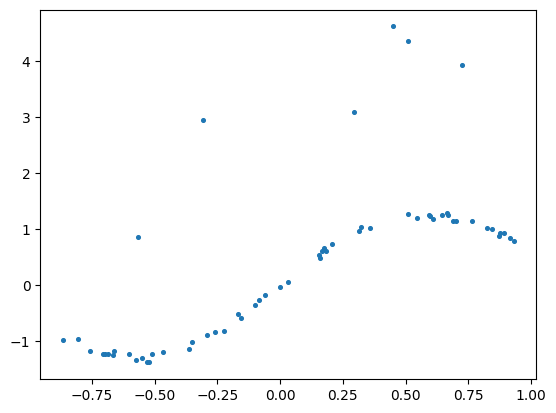

In [53]:
plt.scatter(X, Y, s=7)

In [54]:
m = 60
n = 8

A = np.zeros((m, n))
for i in range(m):
    for j in range(n):
        A[i, j] = utils.Legendre_poly(j, X[i])

# theta = utils.naive_LSE(A, Y) 
theta = np.linalg.lstsq(A, Y, rcond=None)[0]
display(Math(r"\theta=" + utils.np_to_latex(theta)))
display(Math(r"A=" + utils.np_to_latex(A)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Text(0.5, 0, 'x')

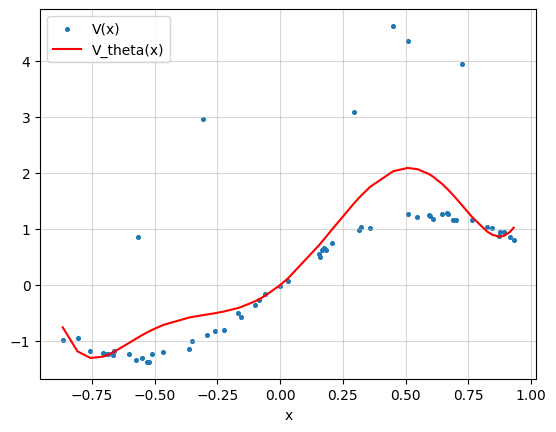

In [55]:
v_estimate_vec = np.array([utils.V_estimate(theta, x) for x in X])

plt.scatter(X, Y, label="V(x)", s=7)
plt.plot(X, v_estimate_vec, label="V_theta(x)", color="red")

plt.legend()
plt.grid(alpha=0.5)
plt.xlabel("x")
# plt.title("Least squares estimation versus ground truth")

Text(0.5, 0, 'x')

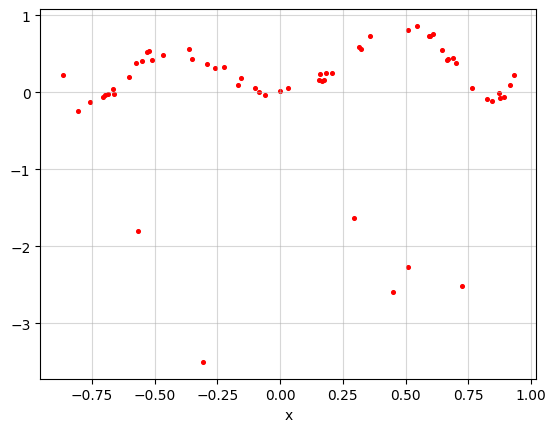

In [56]:
res = A @ theta - Y

plt.scatter(X, res, s=7, color="red")

plt.grid(alpha=0.5)
plt.xlabel("x")
# plt.title("Residuals of LSE")

In [57]:
res_upper_bound = np.max(np.abs(res))
print(res_upper_bound)
eps = res_upper_bound * (1 - 1e-2)
F_eps_grad = utils.F_grad(eps, theta, A, Y)
print(f"eps = {eps}: grad of F_eps = {F_eps_grad}")
print(utils.np_to_latex(F_eps_grad))

3.500412539402735
eps = 3.4654084140087074: grad of F_eps = [ 0.03500413 -0.01082439 -0.01248119  0.0136489   0.00197471 -0.01201828
  0.00516787  0.00733354]
\begin{bmatrix}0.035 & -0.011 & -0.012 & 0.014 & 0.002 & -0.012 & 0.005 & 0.007\end{bmatrix}


In [58]:
with open(data_dir / "validationI.dat", "r") as validation:
    X_val = []
    Y_val = []
    for line in validation:
        x, y = map(float, line.split())
        X_val.append(x)
        Y_val.append(y)
    X_val = np.array(X_val)
    Y_val = np.array(Y_val)

m_val = len(X_val)

# V_theta(x_k)
V_val_estimate = np.array([utils.V_estimate(theta, x) for x in X_val])

val_mse = np.mean((V_val_estimate - Y_val) ** 2)
print(f"MSE={val_mse}")

MSE=0.3457172773966432


In [59]:
A_monomial = np.array([[x**i for i in range(n)] for x in X])
print(f"(monomial) kappa(A'A)={utils.get_condition_number(A_monomial.T @ A_monomial)}")

print(f"(Legendre) kappa(A'A)={utils.get_condition_number(A.T @ A)}")

(monomial) kappa(A'A)=139966.1886854216
(Legendre) kappa(A'A)=315.4474663137863


In [60]:
evalues = np.linalg.eigvals(A.T @ A)
sigma_max_sqr = evalues.max()

t = 1 / sigma_max_sqr
eps = 3
rng = np.random.default_rng(seed=42)
theta_iter = rng.normal(size=n)

threshold = 1e-18
max_iter = 1e6
loss = utils.F(eps, theta_iter, A, Y)
last_loss = float("inf")
iter_cnt = 0

while np.abs(loss - last_loss) >= threshold and iter_cnt < max_iter:
    last_loss = loss.copy()
    theta_iter -= t * utils.F_grad(eps, theta_iter, A, Y)
    loss = utils.F(eps, theta_iter, A, Y)
    iter_cnt += 1
    clear_output()
    print(f"iteration:{iter_cnt} | loss = {loss}")

iteration:3871 | loss = 22.031495273895786


In [61]:
print(theta)
print(theta_iter)

[ 0.36653876  1.5006948   0.20814339 -1.59632225  0.30487261 -0.1499845
  1.22721903 -0.00566753]
[ 0.34975372  1.52339629  0.19552555 -1.59943964  0.25657309 -0.09156117
  1.17369403 -0.0231094 ]


In [62]:
eps_set = 10 ** np.arange(-3, 1.5, 0.5)
MSE_set = []
theta_set = []

for eps in eps_set:
    iter_cnt, final_theta, final_loss = utils.F_gd(A, Y, eps=eps)
    val_mse = utils.get_mse(final_theta, X_val, Y_val)
    MSE_set.append(val_mse)
    theta_set.append(final_theta)
    print(f"eps = {eps:.3f} | {iter_cnt} iterations, loss = {final_loss:.6f}, MSE = {val_mse:.6f}")

MSE_set = np.array(MSE_set)
theta_set = np.array(theta_set)

eps = 0.001 | 28001 iterations, loss = 0.019450, MSE = 0.000604
eps = 0.003 | 9385 iterations, loss = 0.061319, MSE = 0.000532
eps = 0.010 | 2936 iterations, loss = 0.192128, MSE = 0.000538
eps = 0.032 | 1570 iterations, loss = 0.592552, MSE = 0.000279
eps = 0.100 | 1485 iterations, loss = 1.778772, MSE = 0.000278
eps = 0.316 | 886 iterations, loss = 5.251427, MSE = 0.003528
eps = 1.000 | 1793 iterations, loss = 13.950205, MSE = 0.056912
eps = 3.162 | 2076 iterations, loss = 22.106993, MSE = 0.323255
eps = 10.000 | 2086 iterations, loss = 22.170428, MSE = 0.345321


(-4.0, 1.0)

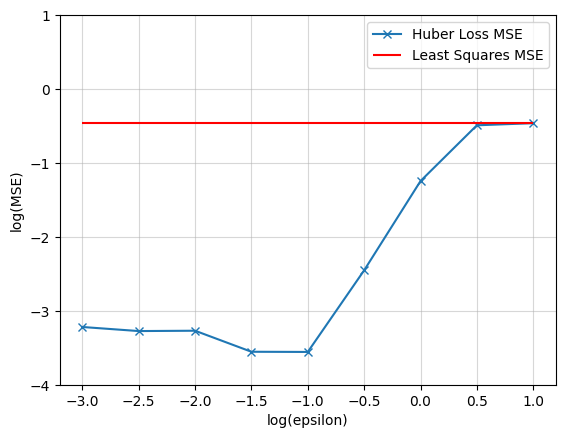

In [63]:
plt.plot(np.log10(eps_set), np.log10(MSE_set), label="Huber Loss MSE", marker="x")
plt.hlines(np.log10(val_mse), xmin=np.log10(eps_set).min(), xmax=np.log10(eps_set).max(), colors="red", label="Least Squares MSE")
plt.xlabel("log(epsilon)")
plt.ylabel("log(MSE)")
plt.grid(alpha=0.5)
plt.legend()
plt.ylim((-4, 1))

optimal: eps = 0.1, theta = [ 0.00378706  1.54857604 -0.00883307 -1.07726548  0.01046181  0.22206392
 -0.00511763 -0.01170662], MSE = 0.00027763299864254836


Text(0.5, 0, 'x')

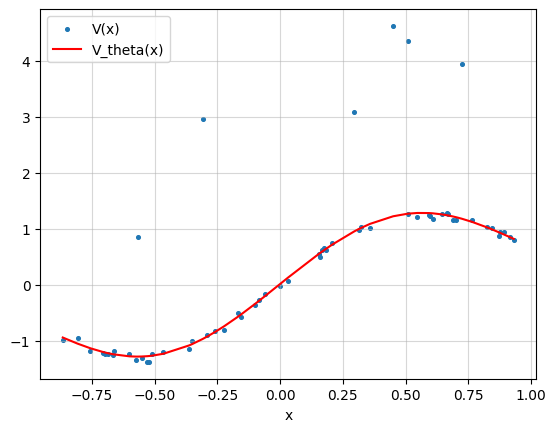

In [64]:
optimal_idx = np.argmin(MSE_set)
theta_optimal = theta_set[optimal_idx]
print(f"optimal: eps = {eps_set[optimal_idx]}, theta = {theta_optimal}, MSE = {MSE_set[optimal_idx]}")

v_estimate_vec = np.array([utils.V_estimate(theta_optimal, x) for x in X])

plt.scatter(X, Y, label="V(x)", s=7)
plt.plot(X, v_estimate_vec, label="V_theta(x)", color="red")

plt.legend()
plt.grid(alpha=0.5)
plt.xlabel("x")

In [65]:
outliers = []
for i, y in enumerate(Y):
    if abs(v_estimate_vec[i] - y) > 0.25:
        outliers.append(i+1)

print(outliers)

[11, 19, 36, 40, 42, 52]


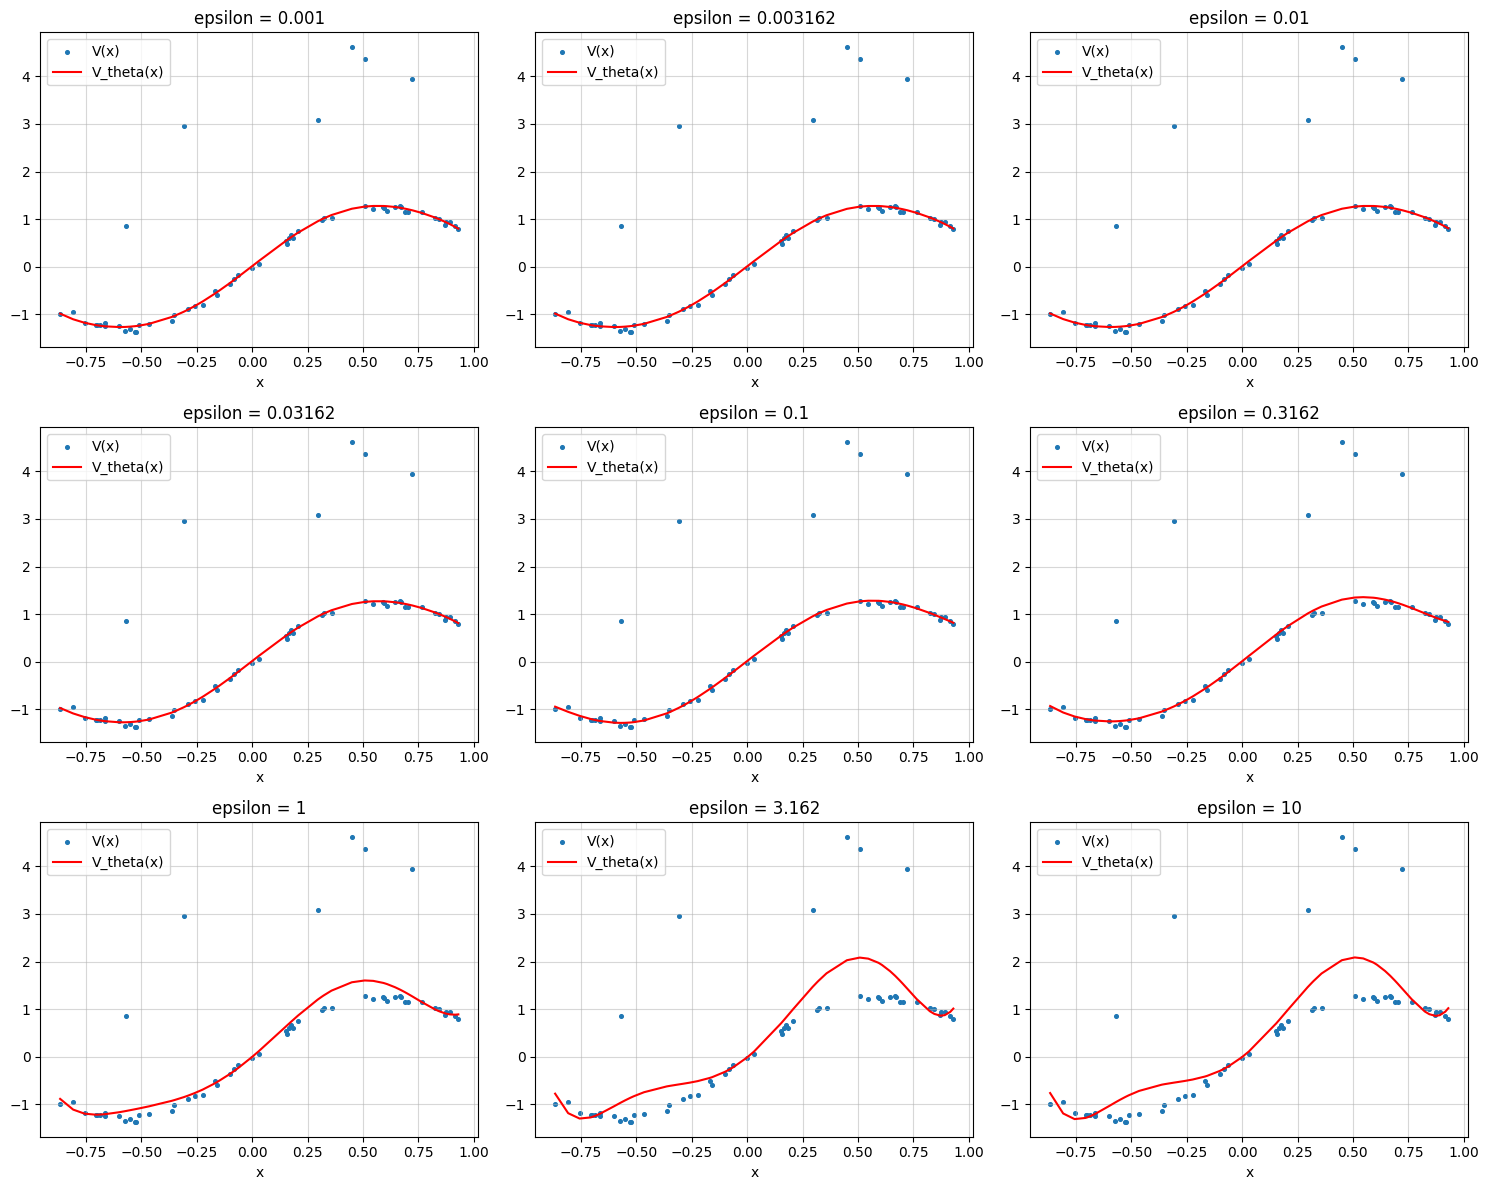

In [66]:
n = len(theta_set)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = np.array(axes).flatten()

for i, theta in enumerate(theta_set):
    v_estimate_vec = np.array([utils.V_estimate(theta, x) for x in X])

    axes[i].scatter(X, Y, label="V(x)", s=7)
    axes[i].plot(X, v_estimate_vec, label="V_theta(x)", color="red")
    axes[i].set_title(f"epsilon = {eps_set[i]:.4g}")
    axes[i].legend()
    axes[i].grid(alpha=0.5)
    axes[i].set_xlabel("x")

# Hide unused subplots
for i in range(n, len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

In [67]:
res_set = []
I_cnt_set = []
lambda_min_set = []

for i, eps in enumerate(eps_set):
    res_set.append(np.array(A @ theta_set[i] - Y))
    mask = np.abs(res_set[i]) < eps
    I_cnt_set.append(np.sum(mask))
    A_I = A[mask, :]
    lambda_min_set.append(np.min(np.linalg.eigvals(A_I.T @ A_I)))
    print(f"eps={eps:.6f}, I_card={I_cnt_set[i]}, lambda_min={lambda_min_set[i]:.6f}")

eps=0.001000, I_card=8, lambda_min=0.000745
eps=0.003162, I_card=8, lambda_min=0.000144
eps=0.010000, I_card=18, lambda_min=0.094833
eps=0.031623, I_card=28, lambda_min=0.144839
eps=0.100000, I_card=52, lambda_min=0.183924
eps=0.316228, I_card=54, lambda_min=0.191187
eps=1.000000, I_card=54, lambda_min=0.191187
eps=3.162278, I_card=59, lambda_min=0.193439
eps=10.000000, I_card=60, lambda_min=0.194078


C:\Users\alex-\AppData\Local\Temp\ipykernel_39592\1771415326.py:9: RuntimeWarning: divide by zero encountered in log10
  plt.plot(np.log10(relative_history), label=f"epsilon={eps}", color=color)


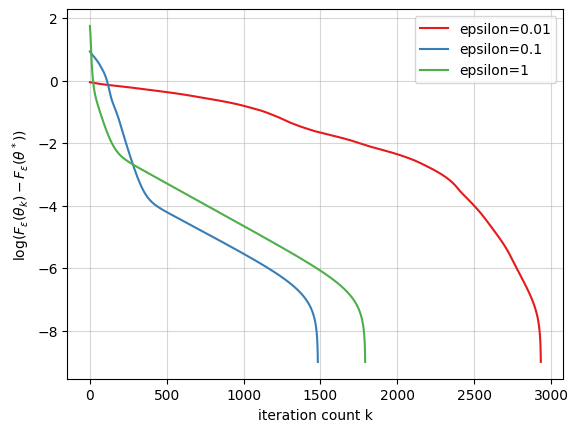

In [72]:
eps_set = (0.01, 0.1, 1)
cmap = plt.get_cmap("Set1")

for i, eps in enumerate(eps_set):
    _, _, final_loss, loss_history = utils.F_gd(A, Y, eps=eps, return_loss_history=True)
    relative_history = loss_history - final_loss
    # color = cmap(i / (len(eps_set) - 1))
    color = cmap(i)
    plt.plot(np.log10(relative_history), label=f"epsilon={eps}", color=color)

plt.xlabel("iteration count k")
plt.ylabel(r"$\log(F_\epsilon(\theta_k)-F_\epsilon(\theta^*))$")
plt.grid(alpha=0.5)
plt.legend()